# 01 · Data Ingestion, Quality Audit and Cleaning

**What this notebook covers**

- Check the raw file fingerprint (SHA-256)
- Validate the schema, category values and value ranges
- Profile data quality: missing values, duplicates and unusual values
- Prove that `reservation_status` leaks the target
- Check the numbers quoted in the docs against the data
- Apply fixed cleaning rules and save the clean dataset and data contract

## 1. Environment setup
### 1.1 Imports

In [1]:
import hashlib
import json
import platform
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

### 1.2 Reproducibility constants and project paths
A fixed project-wide seed (decision #14) and paths resolved from the repository root,
so the notebook runs identically from VS Code or Jupyter.

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOTEBOOK_PREFIX = "01"

# Resolve the repository root regardless of where the kernel was started
# (VS Code starts kernels in notebooks/, Jupyter may start them at the repo root).
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "docs" / "DECISIONS.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Project root not found (no DECISIONS.md in any parent directory).")


PROJECT_ROOT = find_project_root()

PATHS = {
    "raw": PROJECT_ROOT / "data" / "hotel_bookings.csv",
    "clean": PROJECT_ROOT / "data" / "interim" / "hotel_bookings_clean.csv",
    "splits": PROJECT_ROOT / "data" / "processed" / "splits",
    "features": PROJECT_ROOT / "data" / "processed" / "features",
    "artifacts": PROJECT_ROOT / "artifacts",
    "preprocessors": PROJECT_ROOT / "artifacts" / "preprocessors",
    "model_outputs": PROJECT_ROOT / "artifacts" / "model_outputs",
    "models": PROJECT_ROOT / "models",
    "figures": PROJECT_ROOT / "reports" / "figures",
    "tables": PROJECT_ROOT / "reports" / "tables",
    "notebooks": PROJECT_ROOT / "notebooks",
}
for key in ("artifacts", "preprocessors", "model_outputs", "models", "figures", "tables"):
    PATHS[key].mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /home/hasitha-erandika/Documents/Projects/hotel-booking-cancellation-ml


### 1.3 Shared constants and I/O helpers
Column-role constants and small helpers (hashing, JSON I/O, typed CSV reader) used in
every project notebook. They are repeated per notebook by design (no `src/` package,
see `plan.md` §3).

In [3]:
# Columns that must always be treated as categorical strings when re-reading CSVs.
STRING_COLUMNS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "agent", "company",
    "customer_type", "arrival_season",
]
TARGET = "is_canceled"
ID_COLUMN = "booking_id"
LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]

def sha256_file(path: Path, chunk_size: int = 1 << 20) -> str:
    """Streaming SHA-256 of a file (used to fingerprint every artifact)."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(obj: dict, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))


def load_json(path: Path) -> dict:
    if not path.exists():
        raise FileNotFoundError(f"Required artifact missing: {path.relative_to(PROJECT_ROOT)}")
    return json.loads(path.read_text())


def read_frame(path: Path) -> pd.DataFrame:
    """Read a project CSV with categorical columns forced to plain Python strings.

    `keep_default_na=False` + an explicit NA list stops pandas from turning legitimate
    category labels into NaN; numeric columns are parsed normally.
    """
    if not path.exists():
        raise FileNotFoundError(f"Required data file missing: {path.relative_to(PROJECT_ROOT)}")
    frame = pd.read_csv(
        path,
        dtype={col: object for col in STRING_COLUMNS},
        keep_default_na=False,
        na_values=["", "NaN", "nan"],
    )
    present = [c for c in STRING_COLUMNS if c in frame.columns]
    frame[present] = frame[present].astype(object)
    return frame

### Plotting style
One colour scheme for every figure in the project. Figures are saved to `reports/figures/` with the notebook number as prefix.

In [4]:
# One visual language for every figure in the project:
#  - blue = not cancelled, orange = cancelled (validated colour-blind-safe pair)
#  - single-series charts use blue; recessive grey grid; no top/right spines; no dual axes.
COLORS = {
    "not_canceled": "#2a78d6",
    "canceled": "#eb6834",
    "neutral": "#8a8985",
    "ink": "#0b0b0b",
    "ink_muted": "#52514e",
}
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQUENTIAL_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIVERGING_CMAP = mpl.colors.LinearSegmentedColormap.from_list(
    "project_diverging", ["#2a78d6", "#e8e7e3", "#eb6834"]
)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=SERIES_COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": COLORS["ink_muted"],
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlecolor": COLORS["ink"],
    "axes.grid": True,
    "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8,
    "xtick.color": COLORS["ink_muted"],
    "ytick.color": COLORS["ink_muted"],
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def save_figure(fig, name: str) -> Path:
    """Save a figure under reports/figures with this notebook's numeric prefix."""
    path = PATHS["figures"] / f"{NOTEBOOK_PREFIX}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure -> {path.relative_to(PROJECT_ROOT)}")
    return path

### 1.4 Environment report
Library versions are printed so every output in this notebook can be traced to an
exact environment (docs/08 §8.2).

In [5]:
import importlib.metadata as importlib_metadata

def library_versions(packages=("numpy", "pandas", "scikit-learn", "xgboost", "matplotlib", "seaborn", "scipy", "shap", "joblib")) -> dict:
    versions = {"python": sys.version.split()[0], "platform": platform.platform()}
    for package in packages:
        try:
            versions[package] = importlib_metadata.version(package)
        except importlib_metadata.PackageNotFoundError:
            versions[package] = "not installed"
    return versions

LIBRARY_VERSIONS = library_versions()
pd.Series(LIBRARY_VERSIONS, name="version").to_frame()

,version
python,3.11.15
platform,Linux-7.0.0-38-generic-x86_64-with-glibc2.43
numpy,2.4.6
pandas,3.0.3
scikit-learn,1.9.0
xgboost,not installed
matplotlib,3.10.9
seaborn,0.13.2
scipy,1.17.1
shap,not installed


## 2. Data contract
The contract below is the single, explicit definition of what a valid raw file looks
like. It is derived from the data dictionary in `docs/03-data-understanding.md` §3.2.
Any deviation is reported, and hard deviations stop the notebook.

In [6]:
DOCUMENTED_SHA256 = "7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06"
EXPECTED_SHAPE = (119_390, 32)

# column -> expected pandas dtype kind ("i" integer, "f" float, "O" object/string)
EXPECTED_SCHEMA = {
    "hotel": "O", "is_canceled": "i", "lead_time": "i", "arrival_date_year": "i",
    "arrival_date_month": "O", "arrival_date_week_number": "i", "arrival_date_day_of_month": "i",
    "stays_in_weekend_nights": "i", "stays_in_week_nights": "i", "adults": "i",
    "children": "f", "babies": "i", "meal": "O", "country": "O", "market_segment": "O",
    "distribution_channel": "O", "is_repeated_guest": "i", "previous_cancellations": "i",
    "previous_bookings_not_canceled": "i", "reserved_room_type": "O", "assigned_room_type": "O",
    "booking_changes": "i", "deposit_type": "O", "agent": "f", "company": "f",
    "days_in_waiting_list": "i", "customer_type": "O", "adr": "f",
    "required_car_parking_spaces": "i", "total_of_special_requests": "i",
    "reservation_status": "O", "reservation_status_date": "O",
}

EXPECTED_DOMAINS = {
    "hotel": {"Resort Hotel", "City Hotel"},
    "is_canceled": {0, 1},
    "arrival_date_year": {2015, 2016, 2017},
    "arrival_date_month": {"January", "February", "March", "April", "May", "June", "July",
                           "August", "September", "October", "November", "December"},
    "meal": {"BB", "HB", "FB", "SC", "Undefined"},
    "deposit_type": {"No Deposit", "Non Refund", "Refundable"},
    "customer_type": {"Transient", "Transient-Party", "Contract", "Group"},
    "is_repeated_guest": {0, 1},
    "reservation_status": {"Check-Out", "Canceled", "No-Show"},
}

EXPECTED_RANGES = {  # inclusive physical ranges; values outside are reported as quality issues
    "lead_time": (0, 800), "arrival_date_week_number": (1, 53), "arrival_date_day_of_month": (1, 31),
    "stays_in_weekend_nights": (0, 30), "stays_in_week_nights": (0, 60), "adults": (0, 60),
    "babies": (0, 10), "adr": (0, 10_000),
}

## 3. Ingestion with integrity verification
### 3.1 Verify the raw file fingerprint
If the hash differs, the file is a different version from the one the documentation
was computed on, so every downstream number would be unverifiable.

In [7]:
raw_sha256 = sha256_file(PATHS["raw"])
print(f"Raw file SHA-256: {raw_sha256}")
assert raw_sha256 == DOCUMENTED_SHA256, (
    "Raw data fingerprint mismatch - this is not the documented dataset version "
    "(docs/08-reproducibility.md section 8.1)."
)
print("Fingerprint matches the documented dataset version.")

Raw file SHA-256: 7c2ae42a7353905ea136e5c2287f17c92c5435826598bfbb8491c6f0c7b1fc06
Fingerprint matches the documented dataset version.


### 3.2 Load the raw data
Default pandas NA handling is used on the *raw* file on purpose: the source encodes
missing values as `NA` (children) and `NULL` (agent/company/country).

In [8]:
raw_df = pd.read_csv(PATHS["raw"])
print(f"Raw shape: {raw_df.shape}")
assert raw_df.shape == EXPECTED_SHAPE, f"Unexpected raw shape {raw_df.shape}, expected {EXPECTED_SHAPE}"
raw_df.head()

Raw shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 4. Schema validation
### 4.1 Columns and dtypes
Every expected column must exist with the expected dtype kind, and no unexpected
columns may appear.

In [9]:
schema_rows = []
for column, expected_kind in EXPECTED_SCHEMA.items():
    present = column in raw_df.columns
    actual_kind = raw_df[column].dtype.kind if present else None
    # pandas >= 3 may infer the dedicated string dtype (kind "O" or "T"); treat both as text.
    kind_ok = present and (actual_kind == expected_kind or (expected_kind == "O" and actual_kind in {"O", "T", "U"}))
    schema_rows.append({"column": column, "present": present, "expected_kind": expected_kind,
                        "actual_dtype": str(raw_df[column].dtype) if present else None, "ok": kind_ok})

schema_report = pd.DataFrame(schema_rows)
unexpected_columns = sorted(set(raw_df.columns) - set(EXPECTED_SCHEMA))

display(schema_report[~schema_report["ok"]] if (~schema_report["ok"]).any() else "All 32 columns present with expected dtypes.")
assert schema_report["ok"].all(), "Schema dtype/column violations found (see table above)."
assert not unexpected_columns, f"Unexpected columns: {unexpected_columns}"

'All 32 columns present with expected dtypes.'

### 4.2 Category domains and physical ranges
Closed-set categoricals must only contain documented values; numeric columns are
checked against physically plausible ranges (violations are *reported*, not fixed here).

In [10]:
domain_rows = []
for column, allowed in EXPECTED_DOMAINS.items():
    observed = set(raw_df[column].dropna().unique())
    unexpected = observed - allowed
    domain_rows.append({"column": column, "n_observed": len(observed),
                        "unexpected_values": sorted(map(str, unexpected)), "ok": not unexpected})

range_rows = []
for column, (low, high) in EXPECTED_RANGES.items():
    series = raw_df[column]
    out_of_range = int(((series < low) | (series > high)).sum())
    range_rows.append({"column": column, "min": series.min(), "max": series.max(),
                       "allowed_range": f"[{low}, {high}]", "n_out_of_range": out_of_range})

domain_report = pd.DataFrame(domain_rows)
range_report = pd.DataFrame(range_rows)
display(domain_report)
display(range_report)
assert domain_report["ok"].all(), "Unexpected category values found in closed-set columns."

,column,n_observed,unexpected_values,ok
0,hotel,2,[],True
1,is_canceled,2,[],True
2,arrival_date_year,3,[],True
3,arrival_date_month,12,[],True
4,meal,5,[],True
5,deposit_type,3,[],True
6,customer_type,4,[],True
7,is_repeated_guest,2,[],True
8,reservation_status,3,[],True


,column,min,max,allowed_range,n_out_of_range
0,lead_time,0.00,737.0,"[0, 800]",0
1,arrival_date_week_number,1.00,53.0,"[1, 53]",0
2,arrival_date_day_of_month,1.00,31.0,"[1, 31]",0
3,stays_in_weekend_nights,0.00,19.0,"[0, 30]",0
4,stays_in_week_nights,0.00,50.0,"[0, 60]",0
5,adults,0.00,55.0,"[0, 60]",0
6,babies,0.00,10.0,"[0, 10]",0
7,adr,-6.38,5400.0,"[0, 10000]",1


## 5. Data-quality profile (target-agnostic)
### 5.1 Missing values
Missingness is reported with its likely *mechanism*, because the treatment depends on
whether missing means "unknown" or "not applicable" (decision #5).

In [11]:
MISSING_MECHANISM = {
    "children": "Unrecorded, almost certainly 0 (fixed rule: impute 0)",
    "country": "Genuinely unknown origin (fixed rule: explicit 'Unknown' category)",
    "agent": "Structural: booking not made through an agent ('No Agent')",
    "company": "Structural: booking not company-billed ('No Company')",
}

missing_report = (
    raw_df.isna().sum().rename("n_missing").to_frame()
    .assign(pct_missing=lambda d: (d["n_missing"] / len(raw_df) * 100).round(2))
    .query("n_missing > 0")
    .assign(mechanism=lambda d: d.index.map(MISSING_MECHANISM))
    .sort_values("n_missing", ascending=False)
)
both_agent_company_missing = int((raw_df["agent"].isna() & raw_df["company"].isna()).sum())
print(f"Rows missing both agent and company: {both_agent_company_missing:,}")
missing_report

Rows missing both agent and company: 9,760


,n_missing,pct_missing,mechanism
company,112593,94.31,Structural: booking not company-billed ('No Co...
agent,16340,13.69,Structural: booking not made through an agent ...
country,488,0.41,Genuinely unknown origin (fixed rule: explicit...
children,4,0.00,"Unrecorded, almost certainly 0 (fixed rule: im..."


#### Missing values chart
Share of rows missing per column. `company` and `agent` are mostly missing by design (no company or no agent), not because of bad data.

Saved figure -> reports/figures/01_missing_values.png


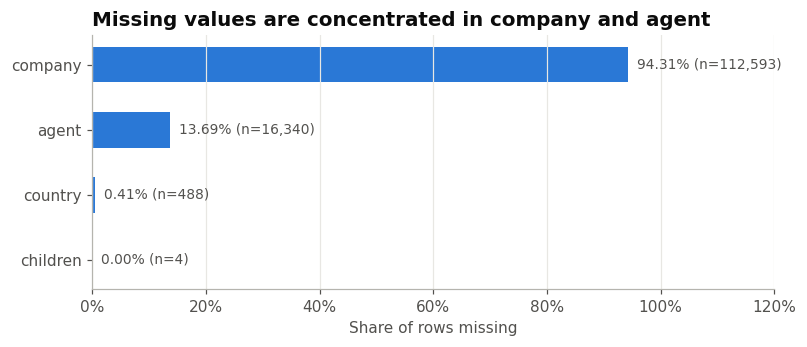

In [12]:
plot_data = missing_report.sort_values("pct_missing")
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(plot_data.index, plot_data["pct_missing"], color=COLORS["not_canceled"], height=0.55)
ax.bar_label(bars, labels=[f"{p:.2f}% (n={n:,})" for p, n in zip(plot_data["pct_missing"], plot_data["n_missing"])],
             padding=6, color=COLORS["ink_muted"], fontsize=9)
ax.set_xlim(0, 120)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(100))
ax.set_xlabel("Share of rows missing")
ax.set_title("Missing values are concentrated in company and agent", loc="left")
ax.grid(axis="y", visible=False)
save_figure(fig, "missing_values")
plt.show()

### 5.2 Duplicate rows
Duplicates are counted two ways:

- **All 32 columns:** the figure quoted in the docs.
- **Modelling columns** (leakage columns removed): what actually matters for training.
  Rows that differ *only* in `reservation_status_date` are the same training example.

In [13]:
modelling_columns = [c for c in raw_df.columns if c not in LEAKAGE_COLUMNS]
dup_all_columns = int(raw_df.duplicated().sum())
dup_modelling_columns = int(raw_df[modelling_columns].duplicated().sum())

duplicate_report = pd.DataFrame({
    "definition": ["Exact match on all 32 columns", "Exact match on 30 modelling columns"],
    "n_duplicates": [dup_all_columns, dup_modelling_columns],
    "pct_of_rows": [dup_all_columns / len(raw_df) * 100, dup_modelling_columns / len(raw_df) * 100],
}).round(2)
duplicate_report

,definition,n_duplicates,pct_of_rows
0,Exact match on all 32 columns,31994,26.80
1,Exact match on 30 modelling columns,32252,27.01


### 5.3 Implausible and edge-case values
Each check is a named, boolean rule so the same definitions can be quoted in the
report and in `DECISIONS.md`.

In [14]:
total_guests_raw = raw_df["adults"] + raw_df["children"].fillna(0) + raw_df["babies"]
total_nights_raw = raw_df["stays_in_weekend_nights"] + raw_df["stays_in_week_nights"]

QUALITY_RULES = {
    "children is missing": raw_df["children"].isna(),
    "children > 3 (implausible)": raw_df["children"] > 3,
    "zero guests (adults=children=babies=0)": total_guests_raw == 0,
    "adults > 4 (large party)": raw_df["adults"] > 4,
    "babies > 2": raw_df["babies"] > 2,
    "adr < 0 (invalid price)": raw_df["adr"] < 0,
    "adr == 0 (free / comped stay)": raw_df["adr"] == 0,
    "adr > 1000 (extreme)": raw_df["adr"] > 1000,
    "zero-night stay": total_nights_raw == 0,
    "meal == 'Undefined'": raw_df["meal"] == "Undefined",
    "market_segment == 'Undefined'": raw_df["market_segment"] == "Undefined",
    "distribution_channel == 'Undefined'": raw_df["distribution_channel"] == "Undefined",
    "reserved != assigned room type": raw_df["reserved_room_type"] != raw_df["assigned_room_type"],
}

quality_report = pd.DataFrame(
    [{"rule": rule, "n_rows": int(mask.sum()), "pct_rows": round(mask.mean() * 100, 3)} for rule, mask in QUALITY_RULES.items()]
)
quality_report

,rule,n_rows,pct_rows
0,children is missing,4,0.003
1,children > 3 (implausible),1,0.001
2,zero guests (adults=children=babies=0),180,0.151
3,adults > 4 (large party),16,0.013
4,babies > 2,2,0.002
5,adr < 0 (invalid price),1,0.001
6,adr == 0 (free / comped stay),1959,1.641
7,adr > 1000 (extreme),1,0.001
8,zero-night stay,715,0.599
9,meal == 'Undefined',1169,0.979


#### Data-quality rules chart
Rows flagged by each rule. The x-axis is on a log scale because the counts range from 1 to about 15,000.

Saved figure -> reports/figures/01_quality_rules.png


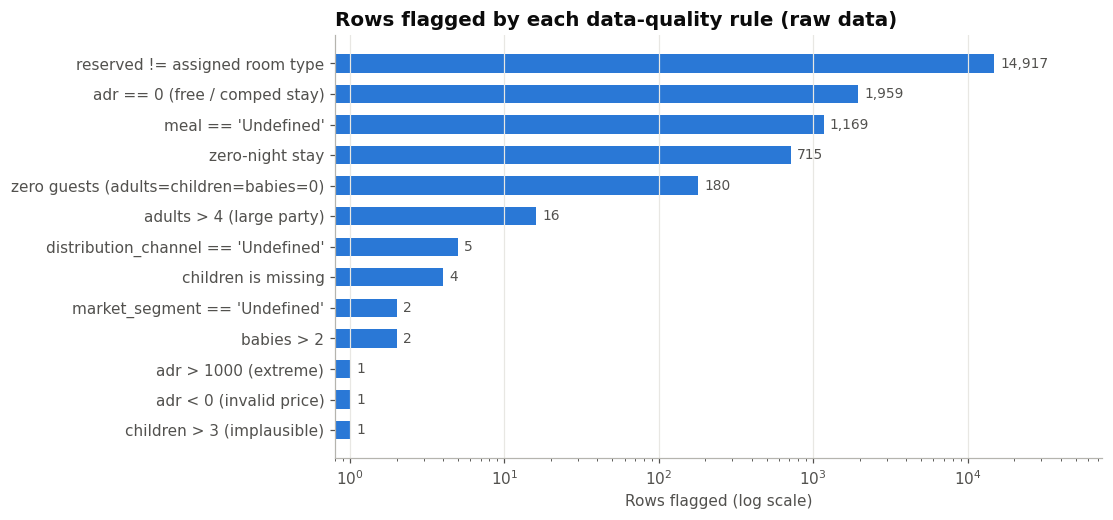

In [15]:
plot_data = quality_report.sort_values("n_rows")
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(plot_data["rule"], plot_data["n_rows"].clip(lower=1), color=COLORS["not_canceled"], height=0.6)
ax.bar_label(bars, labels=[f"{n:,}" for n in plot_data["n_rows"]], padding=4, color=COLORS["ink_muted"], fontsize=9)
ax.set_xscale("log")
ax.set_xlim(0.8, plot_data["n_rows"].max() * 5)
ax.set_xlabel("Rows flagged (log scale)")
ax.set_title("Rows flagged by each data-quality rule (raw data)", loc="left")
ax.grid(axis="y", visible=False)
save_figure(fig, "quality_rules")
plt.show()

### 5.4 Inspect the extreme ADR record and zero-guest bookings
Extreme values are investigated before deciding how to treat them (decision #8):
is the 5,400 ADR row an encoding glitch or a genuine booking? Do zero-guest bookings
cluster in a specific segment?

In [16]:
display(raw_df.loc[raw_df["adr"] == raw_df["adr"].max(),
                   ["hotel", "adults", "children", "babies", "adr", "market_segment", "customer_type", "total_of_special_requests"]])

zero_guest_profile = (
    raw_df.loc[total_guests_raw == 0, ["market_segment", "customer_type"]]
    .value_counts().rename("n_rows").head(10).to_frame()
)
zero_guest_profile

,hotel,adults,children,babies,adr,market_segment,customer_type,total_of_special_requests
48515,City Hotel,2,0.0,0,5400.0,Offline TA/TO,Transient,0


n_rows
market_segment customer_type          
Online TA      Transient            63
Offline TA/TO  Transient            27
Direct         Transient            19
Groups         Transient-Party      16
Complementary  Transient            15
Offline TA/TO  Transient-Party       8
Corporate      Transient             7
               Transient-Party       5
Direct         Transient-Party       5
Groups         Transient             4

### 5.5 Numeric summary
A compact descriptive table for the data dictionary (the numbers are distribution
facts, not target relationships).

In [17]:
numeric_summary = raw_df.describe(percentiles=[0.01, 0.5, 0.99]).T.round(2)
numeric_summary

,count,mean,std,min,1%,50%,99%,max
is_canceled,119390.0,0.37,0.48,0.00,0.0,0.00,1.00,1.0
lead_time,119390.0,104.01,106.86,0.00,0.0,69.00,444.00,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2015.0,2016.00,2017.00,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,2.0,28.00,53.00,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,1.0,16.00,31.00,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.0,1.00,4.00,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,0.0,2.00,10.00,50.0
adults,119390.0,1.86,0.58,0.00,1.0,2.00,3.00,55.0
children,119386.0,0.10,0.40,0.00,0.0,0.00,2.00,10.0
babies,119390.0,0.01,0.10,0.00,0.0,0.00,0.00,10.0


## 6. Target leakage audit
### 6.1 Cross-tabulate `reservation_status` against `is_canceled`

In [18]:
leakage_crosstab = pd.crosstab(raw_df["is_canceled"], raw_df["reservation_status"], margins=True)
leakage_crosstab

reservation_status,Canceled,Check-Out,No-Show,All
is_canceled,,,,
0,0,75166,0,75166
1,43017,0,1207,44224
All,43017,75166,1207,119390


### 6.2 Programmatic proof
The label is fully reconstructable from `reservation_status`. The assertion makes the
finding executable rather than a visual claim.

In [19]:
derived_label = raw_df["reservation_status"].isin(["Canceled", "No-Show"]).astype(int)
n_mismatch = int((derived_label != raw_df["is_canceled"]).sum())
print(f"Mismatches between reservation_status-derived label and is_canceled: {n_mismatch}")
assert n_mismatch == 0, "Expected a perfect (leaking) correspondence."
print("CONFIRMED: reservation_status encodes the target -> both reservation_status columns are dropped.")

Mismatches between reservation_status-derived label and is_canceled: 0
CONFIRMED: reservation_status encodes the target -> both reservation_status columns are dropped.


### 6.3 Status date is always on/after booking outcome
`reservation_status_date` is the date the final status was set, so it is only knowable
after the outcome, so it leaks timing information as well.

In [20]:
status_date = pd.to_datetime(raw_df["reservation_status_date"], errors="coerce")
print(f"Unparseable status dates: {status_date.isna().sum()}")
print(f"Status-date range: {status_date.min().date()} -> {status_date.max().date()}")

Unparseable status dates: 0
Status-date range: 2014-10-17 -> 2017-09-14


## 7. Reconcile documented statistics
`docs/03-data-understanding.md` §3.6 requires that every documented number is reproduced
here. Rows marked `False` must be corrected in the docs (with a `DECISIONS.md` entry);
the notebook is the source of truth.

In [21]:
city = raw_df["hotel"] == "City Hotel"
documented_vs_actual = [
    ("Rows", 119_390, len(raw_df)),
    ("Columns", 32, raw_df.shape[1]),
    ("Exact duplicate rows (all columns)", 31_994, dup_all_columns),
    ("children missing", 4, int(raw_df["children"].isna().sum())),
    ("country missing", 488, int(raw_df["country"].isna().sum())),
    ("agent missing", 16_340, int(raw_df["agent"].isna().sum())),
    ("company missing", 112_593, int(raw_df["company"].isna().sum())),
    ("agent & company both missing", 9_760, both_agent_company_missing),
    ("Not cancelled (raw)", 75_166, int((raw_df["is_canceled"] == 0).sum())),
    ("Cancelled (raw)", 44_224, int((raw_df["is_canceled"] == 1).sum())),
    ("City Hotel bookings", 79_330, int(city.sum())),
    ("Resort Hotel bookings", 40_060, int((~city).sum())),
    ("Room type mismatch rows", 14_917, int(QUALITY_RULES["reserved != assigned room type"].sum())),
    ("Negative adr rows", 1, int(QUALITY_RULES["adr < 0 (invalid price)"].sum())),
    ("Max adr", 5_400.0, float(raw_df["adr"].max())),
    ("Zero adr rows", 1_959, int(QUALITY_RULES["adr == 0 (free / comped stay)"].sum())),
    ("meal Undefined", 1_169, int(QUALITY_RULES["meal == 'Undefined'"].sum())),
    ("market_segment Undefined", 2, int(QUALITY_RULES["market_segment == 'Undefined'"].sum())),
    ("distribution_channel Undefined", 5, int(QUALITY_RULES["distribution_channel == 'Undefined'"].sum())),
    ("Distinct country values (incl. missing)", 178, int(raw_df["country"].nunique(dropna=False))),
]
reconciliation = pd.DataFrame(documented_vs_actual, columns=["statistic", "documented", "actual"])
reconciliation["matches"] = np.isclose(reconciliation["documented"].astype(float), reconciliation["actual"].astype(float))
reconciliation.to_csv(PATHS["tables"] / "01_doc_reconciliation.csv", index=False)
reconciliation

,statistic,documented,actual,matches
0,Rows,119390.0,119390.0,True
1,Columns,32.0,32.0,True
2,Exact duplicate rows (all columns),31994.0,31994.0,True
3,children missing,4.0,4.0,True
4,country missing,488.0,488.0,True
5,agent missing,16340.0,16340.0,True
6,company missing,112593.0,112593.0,True
7,agent & company both missing,9760.0,9760.0,True
8,Not cancelled (raw),75166.0,75166.0,True
9,Cancelled (raw),44224.0,44224.0,True


## 8. Rule-based cleaning (fixed rules only, safe before the split)
### 8.1 Define each cleaning step as a small, named function
Each step returns the transformed frame **and** a log entry, so the cleaning log in the
data contract is generated by the code itself rather than written by hand.

In [22]:
CHILDREN_CAP = 3  # domain constant (decision table in docs/04 section 4.4), not a learned statistic


def add_booking_id(df):
    out = df.copy()
    out.insert(0, ID_COLUMN, np.arange(len(out)))  # traceable back to the raw row number
    return out, "Added booking_id = raw row number (traceability)", 0


def drop_leakage_columns(df):
    out = df.drop(columns=LEAKAGE_COLUMNS)
    return out, f"Dropped target-leakage columns {LEAKAGE_COLUMNS} (decisions #3, #20)", 0


def drop_exact_duplicates(df):
    subset = [c for c in df.columns if c != ID_COLUMN]
    mask = df.duplicated(subset=subset, keep="first")
    return df.loc[~mask].reset_index(drop=True), "Dropped exact duplicates on modelling columns, kept first (decision #4)", int(mask.sum())


def fix_negative_adr(df):
    out = df.copy()
    mask = out["adr"] < 0
    out.loc[mask, "adr"] = 0.0
    return out, "Set negative adr to 0 (invalid price, decision #8)", int(mask.sum())


def impute_and_cap_children(df):
    out = df.copy()
    n_missing = int(out["children"].isna().sum())
    n_capped = int((out["children"] > CHILDREN_CAP).sum())
    out["children"] = out["children"].fillna(0).clip(upper=CHILDREN_CAP).astype(int)
    return out, f"children: NaN -> 0 ({n_missing}), capped at {CHILDREN_CAP} ({n_capped})", n_missing + n_capped


def encode_structural_missing(df):
    """agent/company IDs -> clean string labels; missing -> explicit category (decision #5).

    Placeholder labels deliberately avoid pandas' default NA tokens ("None", "NA", "NULL").
    """
    out = df.copy()
    affected = int(out[["agent", "company", "country"]].isna().sum().sum())
    for column, placeholder in [("agent", "No Agent"), ("company", "No Company")]:
        out[column] = out[column].map(lambda v: placeholder if pd.isna(v) else str(int(v))).astype(object)
    out["country"] = out["country"].fillna("Unknown").astype(object)
    return out, "agent/company -> string IDs with 'No Agent'/'No Company'; country NaN -> 'Unknown'", affected


CLEANING_STEPS = [add_booking_id, drop_leakage_columns, drop_exact_duplicates,
                  fix_negative_adr, impute_and_cap_children, encode_structural_missing]

### 8.2 Run the cleaning pipeline and capture the cleaning log

In [23]:
clean_df = raw_df
cleaning_log = []
for step in CLEANING_STEPS:
    rows_before = len(clean_df)
    clean_df, description, n_affected = step(clean_df)
    cleaning_log.append({"step": step.__name__, "description": description,
                         "rows_before": rows_before, "rows_after": len(clean_df), "values_or_rows_affected": n_affected})

cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df.to_csv(PATHS["tables"] / "01_cleaning_log.csv", index=False)
print(f"Clean shape: {clean_df.shape}")
cleaning_log_df

Clean shape: (87138, 31)


,step,description,rows_before,rows_after,values_or_rows_affected
0,add_booking_id,Added booking_id = raw row number (traceability),119390,119390,0
1,drop_leakage_columns,Dropped target-leakage columns ['reservation_s...,119390,119390,0
2,drop_exact_duplicates,"Dropped exact duplicates on modelling columns,...",119390,87138,32252
3,fix_negative_adr,"Set negative adr to 0 (invalid price, decision...",87138,87138,1
4,impute_and_cap_children,"children: NaN -> 0 (4), capped at 3 (1)",87138,87138,5
5,encode_structural_missing,agent/company -> string IDs with 'No Agent'/'N...,87138,87138,94501


### 8.3 Post-cleaning assertions
The clean dataset must satisfy the contract downstream notebooks rely on.

In [24]:
assert not set(LEAKAGE_COLUMNS) & set(clean_df.columns), "Leakage columns still present."
assert clean_df[ID_COLUMN].is_unique, "booking_id must be unique."
assert not clean_df.drop(columns=[ID_COLUMN]).duplicated().any(), "Duplicates remain after cleaning."
assert clean_df.drop(columns=[ID_COLUMN]).isna().sum().sum() == 0, "Unexpected missing values remain."
assert (clean_df["adr"] >= 0).all(), "Negative adr remains."
assert clean_df["children"].between(0, CHILDREN_CAP).all(), "children outside the allowed range."
assert set(clean_df[TARGET].unique()) == {0, 1}, "Target must be binary."
print("All post-cleaning assertions passed.")

All post-cleaning assertions passed.


### 8.4 Label-conflict check (irreducible noise)
Rows with *identical features* but *different labels* cannot all be predicted correctly
by any model. They are kept (removing them would hide real ambiguity) but counted, as
they bound achievable performance (proposed decision #26).

In [25]:
feature_columns = [c for c in clean_df.columns if c not in (ID_COLUMN, TARGET)]
labels_per_feature_group = clean_df.groupby(feature_columns, dropna=False, sort=False)[TARGET].nunique()
n_conflicting_groups = int((labels_per_feature_group > 1).sum())
print(f"Feature-identical groups with conflicting labels: {n_conflicting_groups:,}")

Feature-identical groups with conflicting labels: 265


### 8.5 Post-dedup target distribution and naive baseline
De-duplication changes the class balance substantially versus the raw figures in the
docs (issue I-01 in `plan.md`). These are the numbers every model must beat.

In [26]:
target_counts = clean_df[TARGET].value_counts().sort_index()
positive_rate = float(clean_df[TARGET].mean())
target_summary = pd.DataFrame({
    "count": target_counts,
    "pct": (target_counts / len(clean_df) * 100).round(2),
}).rename(index={0: "not cancelled (0)", 1: "cancelled (1)"})
print(f"Majority-class accuracy baseline: {1 - positive_rate:.4f}")
print(f"PR-AUC of a random / constant model (= prevalence): {positive_rate:.4f}")
print(f"Negative/positive ratio (scale_pos_weight reference): {(1 - positive_rate) / positive_rate:.3f}")
target_summary

Majority-class accuracy baseline: 0.7272
PR-AUC of a random / constant model (= prevalence): 0.2728
Negative/positive ratio (scale_pos_weight reference): 2.666


,count,pct
is_canceled,,
not cancelled (0),63371,72.72
cancelled (1),23767,27.28


#### Effect of cleaning
Left: row count before and after cleaning (the drop comes from removing duplicates).
Right: cancellation rate before and after. Most removed duplicates were cancelled bookings, so the rate falls.

Saved figure -> reports/figures/01_cleaning_effect.png


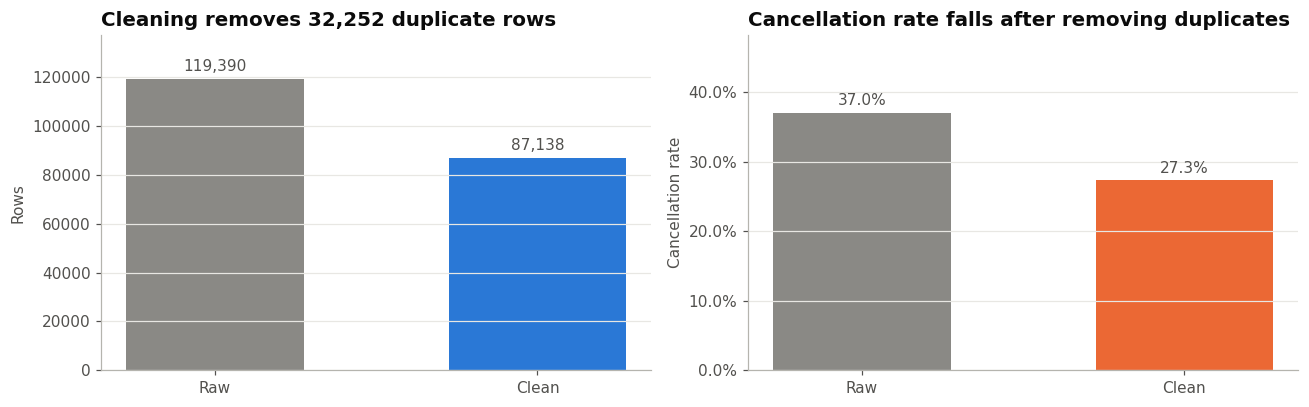

In [27]:
row_counts = pd.Series({"Raw": len(raw_df), "Clean": len(clean_df)})
rates = pd.Series({"Raw": raw_df[TARGET].mean(), "Clean": positive_rate})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bars = axes[0].bar(row_counts.index, row_counts.values, color=[COLORS["neutral"], COLORS["not_canceled"]], width=0.55)
axes[0].bar_label(bars, labels=[f"{v:,}" for v in row_counts.values], padding=3, color=COLORS["ink_muted"])
axes[0].set_ylim(0, row_counts.max() * 1.15)
axes[0].set_ylabel("Rows")
axes[0].set_title(f"Cleaning removes {row_counts['Raw'] - row_counts['Clean']:,} duplicate rows", loc="left")

bars = axes[1].bar(rates.index, rates.values, color=[COLORS["neutral"], COLORS["canceled"]], width=0.55)
axes[1].bar_label(bars, labels=[f"{v:.1%}" for v in rates.values], padding=3, color=COLORS["ink_muted"])
axes[1].set_ylim(0, rates.max() * 1.3)
axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
axes[1].set_ylabel("Cancellation rate")
axes[1].set_title("Cancellation rate falls after removing duplicates", loc="left")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save_figure(fig, "cleaning_effect")
plt.show()

## 9. Export the clean dataset and the data contract
The contract records hashes, schema, the cleaning log and headline statistics. Notebook
02 refuses to run if the clean file's hash does not match this contract.

In [28]:
PATHS["clean"].parent.mkdir(parents=True, exist_ok=True)
clean_df.to_csv(PATHS["clean"], index=False)
clean_sha256 = sha256_file(PATHS["clean"])

data_contract = {
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "notebook": "01_data_ingestion_quality_cleaning.ipynb",
    "raw": {"path": str(PATHS["raw"].relative_to(PROJECT_ROOT)), "sha256": raw_sha256, "shape": list(raw_df.shape)},
    "clean": {
        "path": str(PATHS["clean"].relative_to(PROJECT_ROOT)),
        "sha256": clean_sha256,
        "shape": list(clean_df.shape),
        "columns": {c: str(t) for c, t in clean_df.dtypes.items()},
        "positive_rate": positive_rate,
        "n_label_conflict_groups": n_conflicting_groups,
    },
    "leakage_columns_dropped": LEAKAGE_COLUMNS,
    "duplicates": {"all_columns": dup_all_columns, "modelling_columns": dup_modelling_columns},
    "cleaning_log": cleaning_log,
    "library_versions": LIBRARY_VERSIONS,
}
save_json(data_contract, PATHS["artifacts"] / "data_contract.json")
print(f"Clean dataset -> {PATHS['clean'].relative_to(PROJECT_ROOT)} (sha256 {clean_sha256[:12]}...)")
print("Data contract -> artifacts/data_contract.json")

Clean dataset -> data/interim/hotel_bookings_clean.csv (sha256 5d16feaccd54...)
Data contract -> artifacts/data_contract.json


## 10. Hand-off summary

- **For notebooks 02 and 04:** `data/interim/hotel_bookings_clean.csv` and `artifacts/data_contract.json`.
- **For notebook 10:** the leakage proof (§6) and the reconciliation table (§7).

Findings to log in `DECISIONS.md` (see `plan.md` §7):

- Dedup key = modelling columns → proposed decision **#21** (§5.2 numbers).
- Post-dedup baseline (§8.5) supersedes the 62.96 % figure → proposed decision **#25**.
- Label conflicts kept as irreducible noise → proposed decision **#26**.
- Any `False` row in the reconciliation table (§7) → correct `docs/03-data-understanding.md`.